In [173]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import xarray as xr
import sys
import matplotlib.pyplot as plt
from pathlib import Path
import glob
sys.path.append(str(Path("../src").resolve()))
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.align import align_to_reference_time

## WHICH DAY /DATASET

In [174]:
KA_FILE    = "../data/raw/pallas/20260925_pallasjarvi_rpg-fmcw-35_delft.nc"
W_FILE     = "../data/raw/pallas/20260925_pallasjarvi_rpg-fmcw-94_delft.nc"
W_FILE_GRANADA = "../data/raw/pallas/20260925_pallasjarvi_rpg-fmcw-94_granada.nc"

RANGE_MATCHING_METHOD = "interpolation"            # run 1. In the copied folder for run 2: "gaussian"
Processed_Dataset = f"20260925_pallas_{RANGE_MATCHING_METHOD}_CLARA"   # separate output folder per method
CATEGORIZE_FILE = "../data/raw/pallas/20260925_pallasjarvi_categorize.nc"   # if you use option A in cell 25
MWR_FILE        = "../data/raw/pallas/20260925_pallasjarvi_hatpro-multi_T_h.nc"   # if you use option B in cell 25

Load Both Radars

In [175]:
 # Cell 2 — Load both
# same quantity, same shape -> your old RPG name (CloudnetPy rpg_reader.py keymap, read backwards)
TO_OLD_NAMES = {"lwp": "LWP", "air_pressure": "SurfPres", "radar_frequency": "Freq",
                "integration_time": "SeqIntTime", "number_of_averaged_chirps": "AvgNum",
                "number_of_spectral_samples": "DoppLen"}

def load_cloudnet(path):
    ds = xr.open_dataset(path)
    ds = ds.rename({"time": "Time"})
    ds = ds.assign_coords(Time=ds.Time.values.astype("datetime64[ns]"))
    ds = drop_duplicate_times(ds)
    ds = ds.rename({k: v for k, v in TO_OLD_NAMES.items() if k in ds})
    # back to the units your pipeline expects (CloudnetPy rpg.py convert_units, read backwards)
    if "LWP" in ds:
        ds["LWP"] = ds["LWP"] * 1000.0;        ds["LWP"].attrs["units"] = "g m-2"   # kg m-2 -> g m-2
    if "SurfPres" in ds:
        ds["SurfPres"] = ds["SurfPres"] / 100.0; ds["SurfPres"].attrs["units"] = "hPa"   # Pa -> hPa
    return ds

ds_w  = load_cloudnet(W_FILE)
ds_ka = load_cloudnet(KA_FILE)
ds_w_granada  = load_cloudnet(W_FILE_GRANADA)
print(ds_w); print(ds_ka)

<xarray.Dataset> Size: 449MB
Dimensions:                   (Time: 26916, chirp_sequence: 3, range: 317)
Coordinates:
  * Time                      (Time) datetime64[ns] 215kB 2026-09-25T00:54:34...
  * range                     (range) float32 1kB 119.2 149.1 ... 1.1e+04
Dimensions without coordinates: chirp_sequence
Data variables: (12/55)
    file_code                 (Time) int32 108kB ...
    program_number            (Time) int32 108kB ...
    model_number              int32 4B ...
    Freq                      float32 4B ...
    antenna_separation        float32 4B ...
    antenna_diameter          float32 4B ...
    ...                        ...
    srho_hv                   (Time, range) float32 34MB ...
    kdp                       (Time, range) float32 34MB ...
    differential_attenuation  (Time, range) float32 34MB ...
    altitude                  (Time) float32 108kB ...
    zenith_angle              (Time) float32 108kB ...
    height                    (range) float32

c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
C:\Users\geron\AppData\Local\Temp\ipykernel_24252\2167274257.py:37: RuntimeWarning: All-NaN slice encountered
  floor = np.array([np.nanmax(nf[(h >= lo) & (h < hi)], initial=np.nan) for lo, hi in zip(H_EDGES[:-1], H_EDGES[1:])])


950 m: noise floor CLARA -31.9 | Granada -53.3 dBZ
1950 m: noise floor CLARA -28.4 | Granada -46.9 dBZ
3950 m: noise floor CLARA nan | Granada -40.9 dBZ


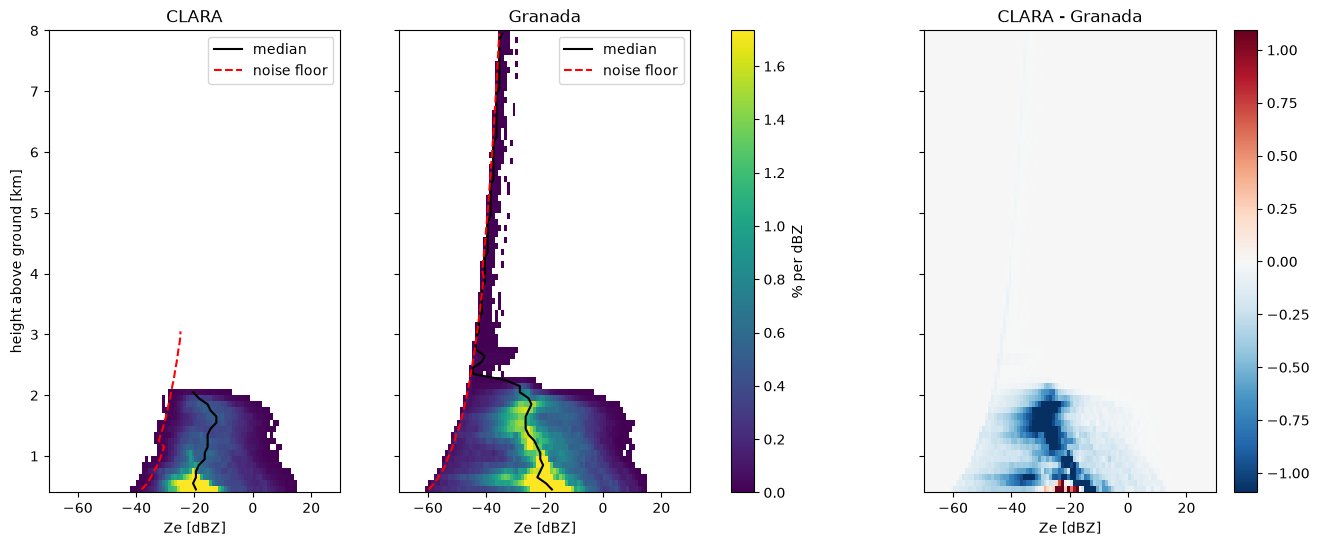

margin  0 dB:   5187 boxes | median -0.83 dB | spread 0.36 dB
margin  5 dB:   5179 boxes | median -0.83 dB | spread 0.36 dB
margin 10 dB:   5004 boxes | median -0.83 dB | spread 0.36 dB
margin 15 dB:   3990 boxes | median -0.80 dB | spread 0.35 dB


C:\Users\geron\AppData\Local\Temp\ipykernel_24252\2167274257.py:96: RuntimeWarning: All-NaN slice encountered
  ax[1].plot(zb[:-1] + 2.5, [np.nanmedian(d.where((ze_g >= a) & (ze_g < a + 5))) for a in zb[:-1]], "ko-")


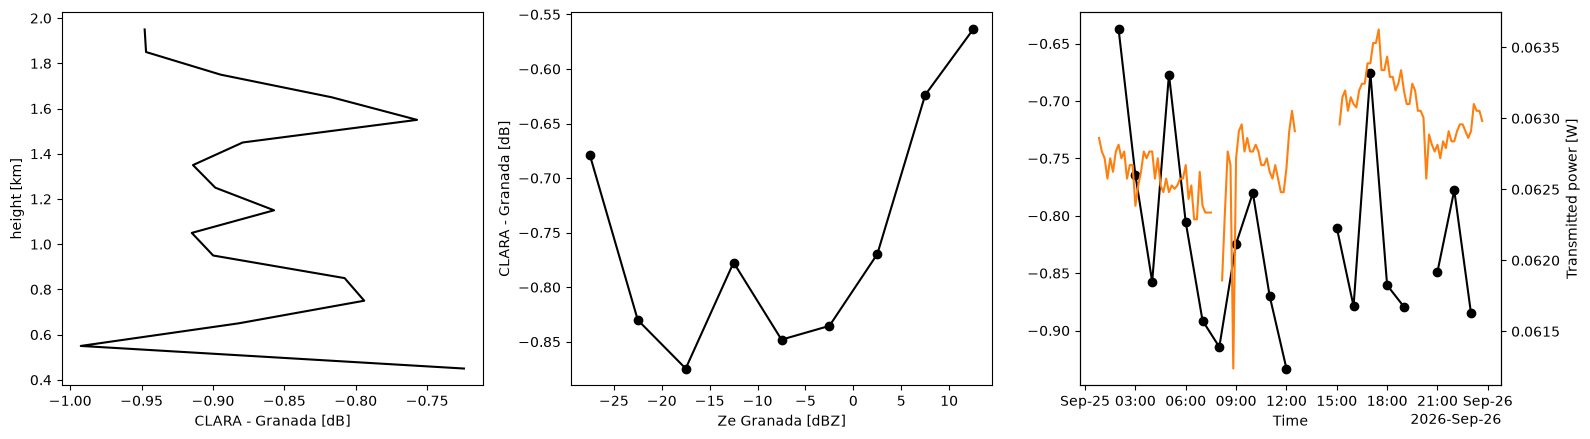

In [176]:
# %%
# ---------- settings ----------
H_EDGES  = np.arange(400, 8001, 100)          # height bins above ground [m]
H_MID    = 0.5 * (H_EDGES[:-1] + H_EDGES[1:])
ZE_EDGES = np.arange(-70, 31, 1)              # 1 dB bins for the CFAD
ground   = float(np.nanmedian(ds_w["altitude"]))   # CLARA ground level [m asl]

def prepare(ds):
    """Rain-free profiles (wet radome!) in the period both radars measured + height above ground per gate."""
    if "rainfall_rate" in ds:
        ds = ds.isel(Time=(ds["rainfall_rate"].fillna(0) <= 0).values)
    t0 = max(ds_w.Time.values[0], ds_w_granada.Time.values[0])
    t1 = min(ds_w.Time.values[-1], ds_w_granada.Time.values[-1])
    ds = ds.sel(Time=slice(t0, t1))
    return ds, ds["height"].values - ground

def noise_floor(ds):
    """Weakest detectable Ze per gate: Ze_min = C + 20 log10(r), C = 0.1 percentile of the
    range-corrected Ze, per chirp (same idea as CloudnetPy's Z_sensitivity)."""
    r_km = ds["range"].values / 1000
    zc = ds["Zh"].values - 20 * np.log10(r_km)
    starts = list(np.atleast_2d(ds["chirp_start_indices"].values)[0].astype(int)) if "chirp_start_indices" in ds else [0]
    out = np.empty(r_km.size)
    for a, b in zip(starts, starts[1:] + [r_km.size]):
        out[a:b] = np.nanpercentile(zc[:, a:b], 0.1) + 20 * np.log10(r_km[a:b])
    return out

def per_height_bin(ds, h):
    """CFAD [% per dBZ of all samples at that height], noise floor per bin, and 30 s x 100 m box means."""
    zh = ds["Zh"].values
    hh = np.broadcast_to(h, zh.shape)
    ok = np.isfinite(zh)
    counts = np.histogram2d(hh[ok], zh[ok], bins=[H_EDGES, ZE_EDGES])[0]
    n_all = np.histogram(hh.ravel(), bins=H_EDGES)[0]
    cfad = 100 * counts / n_all[:, None]
    nf = noise_floor(ds)
    floor = np.array([np.nanmax(nf[(h >= lo) & (h < hi)], initial=np.nan) for lo, hi in zip(H_EDGES[:-1], H_EDGES[1:])])
    # box means in LINEAR Z; member[j, k] = 1 if gate j is in height bin k
    k = np.digitize(h, H_EDGES) - 1
    member = np.zeros((h.size, H_MID.size))
    inside = (k >= 0) & (k < H_MID.size)
    member[np.flatnonzero(inside), k[inside]] = 1
    boxes = xr.Dataset({"z":   (("Time", "height"), np.where(ok, 10 ** (zh / 10), 0) @ member),
                        "n":   (("Time", "height"), ok @ member),
                        "all": (("Time", "height"), np.tile(member.sum(0), (zh.shape[0], 1)))},
                       coords={"Time": ds.Time.values, "height": H_MID}).resample(Time="30s").sum()
    ze_box = 10 * np.log10(boxes.z / boxes.n)        # mean over gates with echo
    coverage = boxes.n / boxes["all"]                # fraction of the box with echo
    return cfad, floor, ze_box, coverage

def median_per_height(cfad):
    mid = 0.5 * (ZE_EDGES[:-1] + ZE_EDGES[1:])
    return np.array([mid[np.searchsorted(np.cumsum(c) / c.sum(), 0.5)] if c.sum() > 0 else np.nan for c in cfad])

clara,   h_clara   = prepare(ds_w)
granada, h_granada = prepare(ds_w_granada)
cfad_c, floor_c, ze_c, cov_c = per_height_bin(clara,   h_clara)
cfad_g, floor_g, ze_g, cov_g = per_height_bin(granada, h_granada)
ze_c, ze_g, cov_c, cov_g = xr.align(ze_c, ze_g, cov_c, cov_g, join="inner")   # same 30 s boxes
for h in (1000, 2000, 4000):
    i = np.searchsorted(H_EDGES, h) - 1
    print(f"{H_MID[i]:.0f} m: noise floor CLARA {floor_c[i]:.1f} | Granada {floor_g[i]:.1f} dBZ")

# %%
# ---------- CFADs ----------
fig, ax = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
vmax = np.nanpercentile(np.r_[cfad_c.ravel(), cfad_g.ravel()], 99.5)
for a, cf, fl, name in [(ax[0], cfad_c, floor_c, "CLARA"), (ax[1], cfad_g, floor_g, "Granada")]:
    m = a.pcolormesh(ZE_EDGES, H_EDGES / 1000, np.where(cf > 0, cf, np.nan), vmin=0, vmax=vmax)
    a.plot(median_per_height(cf), H_MID / 1000, "k-", label="median")
    a.plot(fl, H_MID / 1000, "r--", label="noise floor")
    a.set_title(name); a.set_xlabel("Ze [dBZ]"); a.legend()
fig.colorbar(m, ax=ax[:2], label="% per dBZ")
diff = cfad_c - cfad_g; lim = np.nanpercentile(np.abs(diff), 99)
m = ax[2].pcolormesh(ZE_EDGES, H_EDGES / 1000, diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[2].set_title("CLARA - Granada"); ax[2].set_xlabel("Ze [dBZ]"); fig.colorbar(m, ax=ax[2])
ax[0].set_ylabel("height above ground [km]")
plt.show()

# %%
# ---------- offset from boxes where BOTH radars see the cloud well above their noise ----------
floor = xr.DataArray(np.fmax(floor_c, floor_g), dims="height", coords={"height": H_MID})
dZ = ze_c - ze_g
for margin in (0, 5, 10, 15):     # real offset: same for all margins; sensitivity artefact: changes
    good = (cov_c >= 0.9) & (cov_g >= 0.9) & (ze_c > floor + margin) & (ze_g > floor + margin)
    v = dZ.where(good).values; v = v[np.isfinite(v)]
    print(f"margin {margin:2d} dB: {v.size:6d} boxes | median {np.median(v):+.2f} dB | "
          f"spread {1.4826 * np.median(np.abs(v - np.median(v))):.2f} dB")

good = (cov_c >= 0.9) & (cov_g >= 0.9) & (ze_c > floor + 10) & (ze_g > floor + 10)
d = dZ.where(good)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(d.median("Time"), H_MID / 1000, "k-")                                  # vs height
ax[0].set_xlabel("CLARA - Granada [dB]"); ax[0].set_ylabel("height [km]")
zb = np.arange(-60, 21, 5)                                                       # vs signal strength
ax[1].plot(zb[:-1] + 2.5, [np.nanmedian(d.where((ze_g >= a) & (ze_g < a + 5))) for a in zb[:-1]], "ko-")
ax[1].set_xlabel("Ze Granada [dBZ]"); ax[1].set_ylabel("CLARA - Granada [dB]")
d.median("height").resample(Time="1h").median().plot(ax=ax[2], marker="o", color="k")  # vs time
if "transmitted_power" in clara:
    clara["transmitted_power"].resample(Time="10min").median().plot(ax=ax[2].twinx(), color="tab:orange")
plt.tight_layout(); plt.show()

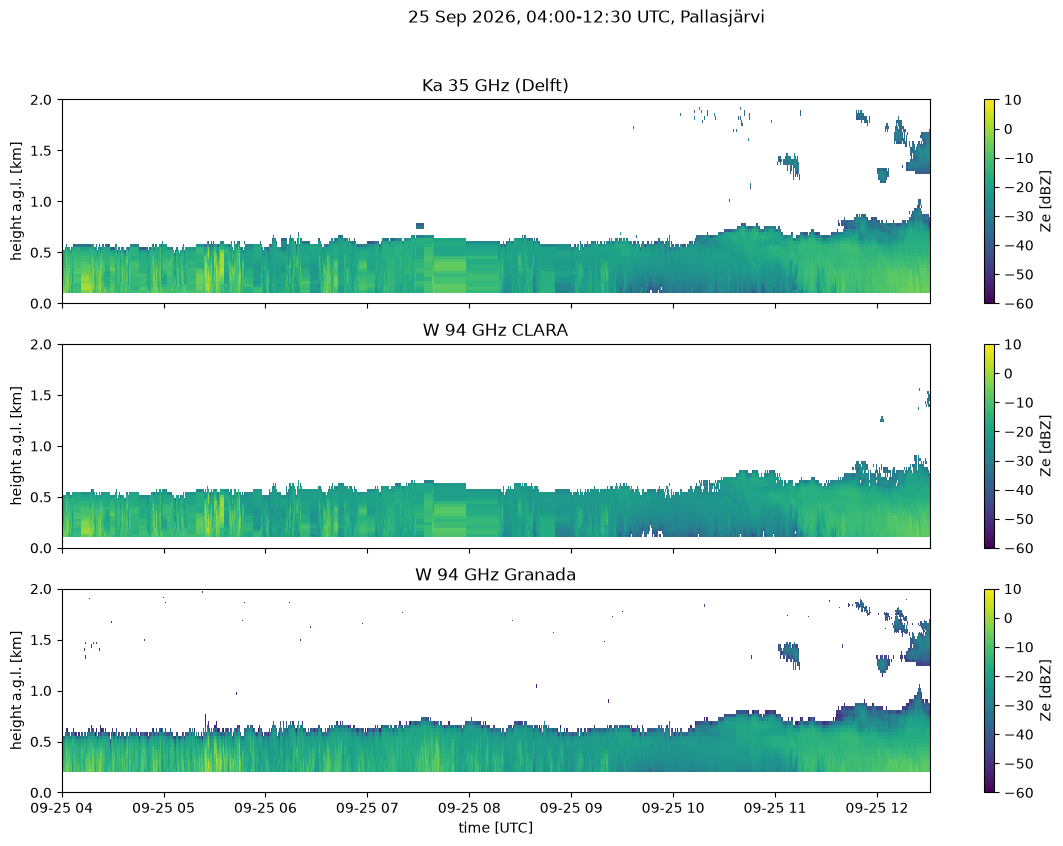

25 Sep 2026, 04:00-12:30 UTC, Pallasjärvi
   Ka 35 GHz (Delft) :  19919 cloud boxes ( 93.6 % of Granada)
   W 94 GHz CLARA    :  17730 cloud boxes ( 83.4 % of Granada)
   W 94 GHz Granada  :  21271 cloud boxes (100.0 % of Granada)


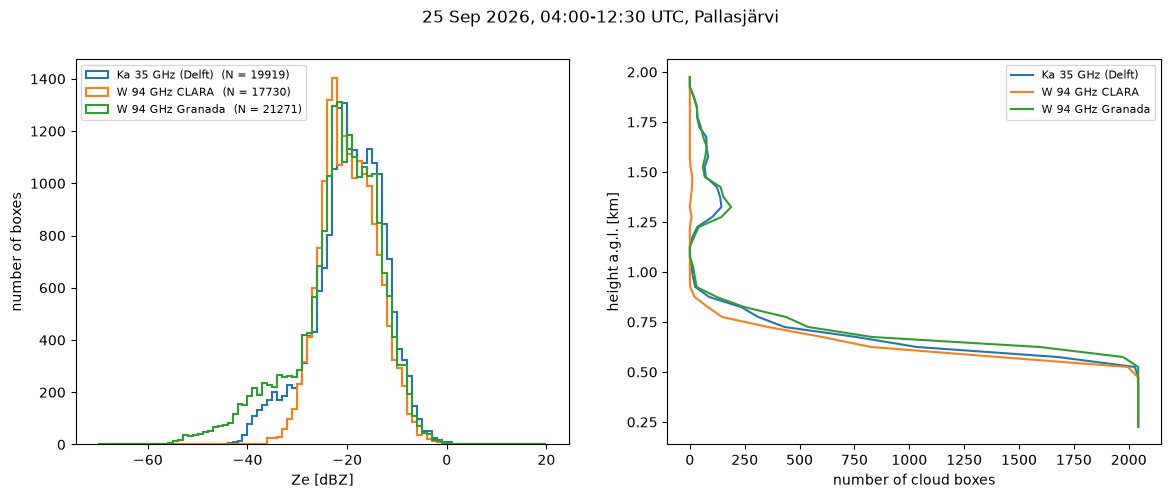

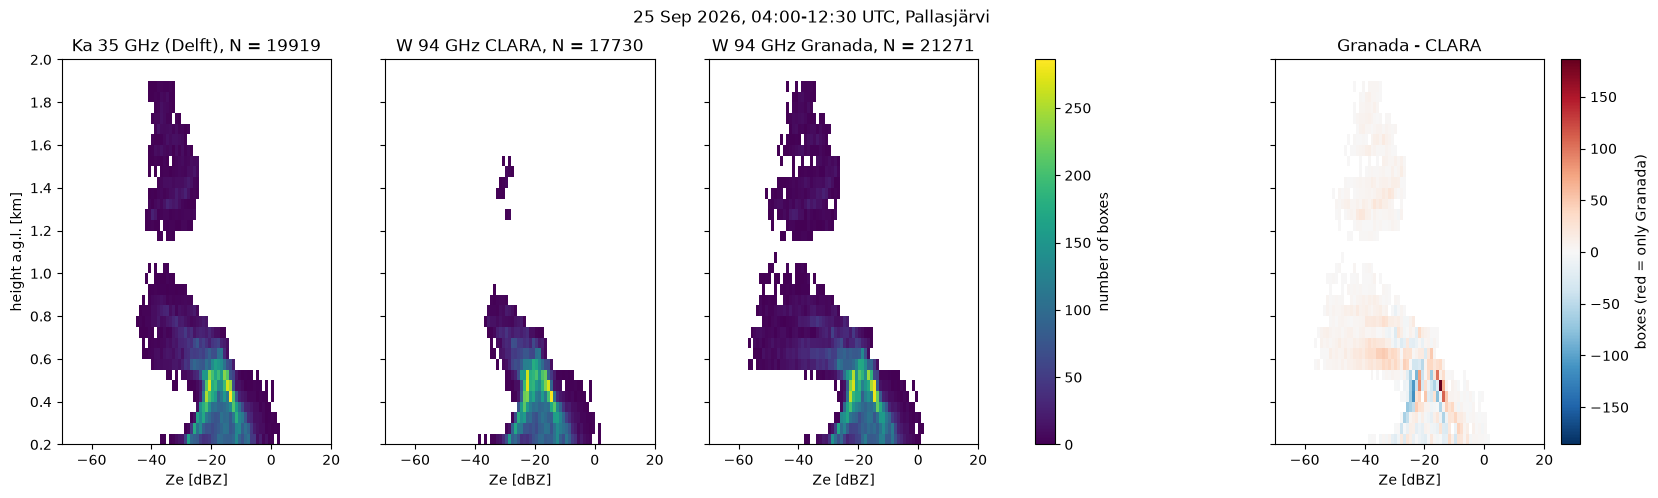

In [177]:
# %%
# ---------- cases: day + time window (UTC) used for the LWC comparison ----------
CASES = [("20260925", "2026-09-25 04:00", "2026-09-25 12:30")]
H_MAX   = 2000                                  # [m above ground] shown / used
H_EDGES = np.arange(200, H_MAX + 1, 50)         # 50 m bins (>= Granada's 36 m gates)
H_MID   = 0.5 * (H_EDGES[:-1] + H_EDGES[1:])
ZE_EDGES = np.arange(-70, 21, 1)                # 1 dB bins
BOX = "10s"                                     # common time step for the shared cloud mask
NAMES = ["Ka 35 GHz (Delft)", "W 94 GHz CLARA", "W 94 GHz Granada"]

def load_case(day, t0, t1):
    """The three radars for one case: rain-free profiles in the window, height above ground per gate."""
    out = []
    for f in [f"../data/raw/pallas/{day}_pallasjarvi_rpg-fmcw-35_delft.nc",
              f"../data/raw/pallas/{day}_pallasjarvi_rpg-fmcw-94_delft.nc",
              f"../data/raw/pallas/{day}_pallasjarvi_rpg-fmcw-94_granada.nc"]:
        ds = load_cloudnet(f).sel(Time=slice(t0, t1))
        if "rainfall_rate" in ds:                                   # wet radome -> remove
            ds = ds.isel(Time=(ds["rainfall_rate"].fillna(0) <= 0).values)
        out.append(ds)
    ground = float(np.nanmedian(out[0]["altitude"]))              # Ka ground level [m asl], same for all three
    return out, [ds["height"].values - ground for ds in out]

def to_common_grid(ds, h):
    """Mean Ze (linear average) and echo coverage in BOX x 50 m boxes -> all radars on the same grid."""
    zh = ds["Zh"].values
    ok = np.isfinite(zh)
    k = np.digitize(h, H_EDGES) - 1                                 # height bin of every gate
    member = np.zeros((h.size, H_MID.size))
    inside = (k >= 0) & (k < H_MID.size)
    member[np.flatnonzero(inside), k[inside]] = 1
    b = xr.Dataset({"z":   (("Time", "height"), np.where(ok, 10 ** (zh / 10), 0) @ member),
                    "n":   (("Time", "height"), ok @ member),
                    "all": (("Time", "height"), np.tile(member.sum(0), (zh.shape[0], 1)))},
                   coords={"Time": ds.Time.values, "height": H_MID}).resample(Time=BOX).sum()
    return 10 * np.log10(b.z / b.n), b.n / b["all"]

for day, t0, t1 in CASES:
    radars, heights = load_case(day, t0, t1)
    label = f"{pd.Timestamp(t0):%d %b %Y}, {pd.Timestamp(t0):%H:%M}-{pd.Timestamp(t1):%H:%M} UTC, Pallasjärvi"

    # ----- 1. time-height plots, native resolution of each radar -----
    fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True, sharey=True)
    for a, ds, h, name in zip(ax, radars, heights, NAMES):
        m = a.pcolormesh(ds.Time.values, h / 1000, ds["Zh"].values.T, vmin=-60, vmax=10, cmap="viridis", shading="nearest")
        a.set_title(name); a.set_ylabel("height a.g.l. [km]"); a.set_ylim(0, H_MAX / 1000)
        fig.colorbar(m, ax=a, label="Ze [dBZ]")
    ax[-1].set_xlabel("time [UTC]"); fig.suptitle(label)
    plt.show()

    # ----- 2. all radars on the same 10 s x 50 m boxes; only times when ALL three measured -----
    grids = [to_common_grid(ds, h) for ds, h in zip(radars, heights)]
    ze  = xr.align(*[g[0] for g in grids], join="inner")
    cov = xr.align(*[g[1] for g in grids], join="inner")
    measured = cov[0].notnull() & cov[1].notnull() & cov[2].notnull()   # no box during scans/gaps of any radar
    detected = [(c >= 0.5) & measured for c in cov]                     # each radar's OWN detections
    n_det = [int(d.sum()) for d in detected]
    print(label)
    for name, n in zip(NAMES, n_det):
        print(f"   {name:18s}: {n:6d} cloud boxes ({100 * n / n_det[2]:5.1f} % of Granada)")

    # ----- 3. counts: histograms, boxes per height, CFADs -----
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for z, d, name in zip(ze, detected, NAMES):
        v = z.where(d).values; v = v[np.isfinite(v)]
        ax[0].hist(v, bins=ZE_EDGES, histtype="step", lw=1.5, label=f"{name}  (N = {v.size})")
        ax[1].plot(d.sum("Time"), H_MID / 1000, lw=1.5, label=name)       # cloud boxes per height
    ax[0].set_xlabel("Ze [dBZ]"); ax[0].set_ylabel("number of boxes"); ax[0].legend(fontsize=8)
    ax[1].set_xlabel("number of cloud boxes"); ax[1].set_ylabel("height a.g.l. [km]"); ax[1].legend(fontsize=8)
    fig.suptitle(label); plt.show()

    cfads = []
    for z, d in zip(ze, detected):
        v = z.where(d).values; ok = np.isfinite(v)
        cfads.append(np.histogram2d(np.broadcast_to(H_MID, v.shape)[ok], v[ok], bins=[H_EDGES, ZE_EDGES])[0])
    fig, ax = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
    vmax = max(c.max() for c in cfads)
    for a, c, name, n in zip(ax, cfads, NAMES, n_det):
        pm = a.pcolormesh(ZE_EDGES, H_EDGES / 1000, np.where(c > 0, c, np.nan), vmin=0, vmax=vmax, cmap="viridis")
        a.set_title(f"{name}, N = {n}"); a.set_xlabel("Ze [dBZ]")
    fig.colorbar(pm, ax=ax[:3], label="number of boxes")
    diff = cfads[2] - cfads[1]; lim = np.abs(diff).max()
    pd_ = ax[3].pcolormesh(ZE_EDGES, H_EDGES / 1000, np.where(diff != 0, diff, np.nan), cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax[3].set_title("Granada - CLARA"); ax[3].set_xlabel("Ze [dBZ]")
    fig.colorbar(pd_, ax=ax[3], label="boxes (red = only Granada)")
    ax[0].set_ylabel("height a.g.l. [km]"); fig.suptitle(label); plt.show()

In [178]:
# Keep the morning programs. "Pallas high" and "Pallas long" share the same range grid
# (14.9 / 13.5 / 34.1 m) and differ only in integration time and Doppler length, so for
# range matching they are interchangeable.
KA_MORNING_RES = (14.9, 13.5, 34.1)

def keep_program(ds, res, tol=0.1):
    """Keep only profiles whose per-chirp range resolution matches `res`."""
    rr = np.atleast_2d(ds["range_resolution"].values)
    keep = np.all(np.abs(rr - np.array(res, float)) < tol, axis=1)
    print(f"kept {keep.sum()} of {keep.size} profiles | "
          f"{ds.Time.values[keep][0]} -> {ds.Time.values[keep][-1]}")
    return ds.isel(Time=keep)

ds_ka = keep_program(ds_ka, KA_MORNING_RES)

kept 21680 of 26916 profiles | 2026-09-25T00:54:34.313950538 -> 2026-09-25T23:42:09.341125488


In [179]:
with ds_ka as d:
    for v in ["SeqIntTime", "AvgNum", "DoppLen"]:
        print(f"{v:12s} {np.asarray(d[v].values).ravel()}")

SeqIntTime   [0.45789346 0.36631477 0.18315738 ... 0.9157869  0.73262954 0.36631477]
AvgNum       [4096 4096 2048 ... 8192 8192 4096]
DoppLen      [256 256 128 ... 512 512 256]


In [180]:

c   = 299792458.0
lam = c / (float(ds_ka["Freq"].values.flat[0]) * 1e9)

max_vel = ds_ka["nyquist_velocity"].values[0, ds_ka["chirp_start_indices"].values[0].astype(int)]
avg_num = ds_ka["AvgNum"].values[0, :].astype(float)
seq_int = ds_ka["SeqIntTime"].values[0, :]

T_chirp = seq_int / avg_num
print("lambda [mm]      :", lam * 1000)
print("chirp spacing [us]:", T_chirp * 1e6)
print("PRF from MaxVel  :", 4.0 * max_vel / lam)
print("AvgNum  :", avg_num )
print("v_Nyq implied    :", lam / (4.0 * T_chirp))

lambda [mm]      : 8.5654988
chirp spacing [us]: [111.79039575  89.4323166   89.4323166 ]
PRF from MaxVel  : [12260.061   9122.932   6123.1245]
AvgNum  : [4096. 4096. 2048.]
v_Nyq implied    : [19.1552654  23.94408175 23.94408175]


In [181]:

c   = 299792458.0
lam = c / (float(ds_w["Freq"].values.flat[0]) * 1e9)

max_vel = ds_w["nyquist_velocity"].values[0, ds_w["chirp_start_indices"].values[0].astype(int)]
avg_num = ds_w["AvgNum"].values[0, :].astype(float)
seq_int = ds_w["SeqIntTime"].values[0, :]

T_chirp = seq_int / avg_num
print("lambda [mm]      :", lam * 1000)
print("chirp spacing [us]:", T_chirp * 1e6)
print("PRF from MaxVel  :", 4.0 * max_vel / lam)
print("AvgNum  :", avg_num)
print("v_Nyq implied    :", lam / (4.0 * T_chirp))

lambda [mm]      : 3.189281468085106
chirp spacing [us]: [111.79039575  89.4323166   89.4323166 ]
PRF from MaxVel  : [12259.182  9122.276  6122.685]
AvgNum  : [4096. 4096. 2048.]
v_Nyq implied    : [7.13227967 8.91534959 8.91534959]


In [182]:
import glob
import numpy as np
import xarray as xr
from pathlib import Path


def check_range_sampling(ds, label=""):
    """
    Compare RPG's reported range resolution with the actual gate spacing,
    per chirp. Reads metadata from the first file, then confirms every other
    file in the folder uses the same chirp table.
    """
    rr = ds["range_resolution"].values[0]
    starts = ds["chirp_start_indices"].values[0].astype(int)
    ends = list(starts[1:]) + [ds.sizes["range"]]
    print(f"--- {label}")
    for c, (i0, i1) in enumerate(zip(starts, ends)):
        g = ds["range"].values[i0:i1]
        spacing = float(np.median(np.diff(g)))
        factor = float(rr[c]) / spacing
        status = "independent" if factor <= 1.01 else "CORRELATED"   # 1.01: float rounding
        print(f"  chirp {c+1}: gates {g[0]:6.0f}-{g[-1]:6.0f} m | {g.size:3d} gates | spacing {spacing:5.1f} m | "
              f"RangeRes {float(rr[c]):5.1f} m | oversampling x{factor:.2f}  -> {status}")

check_range_sampling(ds_ka, "Ka-band")
check_range_sampling(ds_w,  "W-band")

--- Ka-band
  chirp 1: gates    119-  1163 m |  36 gates | spacing  29.8 m | RangeRes  14.9 m | oversampling x0.50  -> independent
  chirp 2: gates   1192-  3011 m |  62 gates | spacing  29.8 m | RangeRes  13.5 m | oversampling x0.45  -> independent
  chirp 3: gates   3041- 10996 m | 219 gates | spacing  37.7 m | RangeRes  34.1 m | oversampling x0.90  -> independent
--- W-band
  chirp 1: gates    119-  1163 m |  36 gates | spacing  29.8 m | RangeRes  14.9 m | oversampling x0.50  -> independent
  chirp 2: gates   1192-  3011 m |  62 gates | spacing  29.8 m | RangeRes  13.5 m | oversampling x0.45  -> independent
  chirp 3: gates   3041- 10996 m | 219 gates | spacing  37.7 m | RangeRes  34.1 m | oversampling x0.90  -> independent


In [183]:
rr = pd.DataFrame(ds_ka["range_resolution"].values).round(1)
rr["Time"] = ds_ka.Time.values
print(rr.groupby(list(rr.columns[:-1]), dropna=False)["Time"].agg(["min", "max", "count"]))

                                              min  \
0    1    2                                         
14.9 13.5 34.099998 2026-09-25 00:54:34.313950538   

                                              max  count  
0    1    2                                               
14.9 13.5 34.099998 2026-09-25 23:42:09.341125488  21680  


## Radar seperation and beam mismatch

In [184]:
import numpy as np
import glob

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000.0
    p1, p2 = np.radians([lat1, lat2])
    a = (np.sin((p2-p1)/2)**2
         + np.cos(p1)*np.cos(p2)*np.sin(np.radians(lon2-lon1)/2)**2)
    return 2*R*np.arcsin(np.sqrt(a))


def beam_overlap(d, hpbw_a, hpbw_b, heights):
    """Fractional area overlap of two circular footprints separated by d."""
    h = np.asarray(heights, float)
    ra = h * np.tan(np.radians(hpbw_a)/2)
    rb = h * np.tan(np.radians(hpbw_b)/2)
    frac = np.zeros_like(h)
    for i, (R1, R2) in enumerate(zip(ra, rb)):
        if d >= R1 + R2:
            frac[i] = 0.0
        elif d <= abs(R1 - R2):
            frac[i] = 1.0
        else:
            a1 = np.arccos((d**2 + R1**2 - R2**2)/(2*d*R1))
            a2 = np.arccos((d**2 + R2**2 - R1**2)/(2*d*R2))
            area = (R1**2*(a1 - np.sin(2*a1)/2) + R2**2*(a2 - np.sin(2*a2)/2))
            frac[i] = area / (np.pi * min(R1, R2)**2)
    return 2*ra, 2*rb, frac



lat_ka, lon_ka = float(ds_ka["latitude"].median()), float(ds_ka["longitude"].median())
lat_w,  lon_w  = float(ds_w["latitude"].median()),  float(ds_w["longitude"].median())
hpbw_ka, hpbw_w = float(ds_ka["half_power_beam_width"]), float(ds_w["half_power_beam_width"])

sep = haversine_m(lat_ka, lon_ka, lat_w, lon_w)
print(f"separation      : {sep:.1f} m")
print(f"HPBW Ka / W     : {hpbw_ka:.3f} / {hpbw_w:.3f} deg")

hs = np.array([500., 750., 1000., 1400., 2000.])
Dka, Dw, frac = beam_overlap(sep, hpbw_ka, hpbw_w, hs)
for h, a, b, f in zip(hs, Dka, Dw, frac):
    print(f"  h={h:5.0f} m: beams {a:5.1f} / {b:5.1f} m | "
          f"separation {sep/(0.5*(a+b)):5.2f} beamwidths | overlap {f:.2f}")

separation      : 0.0 m
HPBW Ka / W     : 0.840 / 0.550 deg
  h=  500 m: beams   7.3 /   4.8 m | separation  0.00 beamwidths | overlap 1.00
  h=  750 m: beams  11.0 /   7.2 m | separation  0.00 beamwidths | overlap 1.00
  h= 1000 m: beams  14.7 /   9.6 m | separation  0.00 beamwidths | overlap 1.00
  h= 1400 m: beams  20.5 /  13.4 m | separation  0.00 beamwidths | overlap 1.00
  h= 2000 m: beams  29.3 /  19.2 m | separation  0.00 beamwidths | overlap 1.00


In [185]:
print(f"Ka: {lat_ka:.7f}, {lon_ka:.7f}")
print(f"W : {lat_w:.7f}, {lon_w:.7f}")

Ka: 68.0226974, 24.1595039
W : 68.0226974, 24.1595039


In [186]:
print("W DualPol:", int(ds_w["dual_polarization"]), "| Ka DualPol:", int(ds_ka["dual_polarization"]))

W DualPol: 2 | Ka DualPol: 2


In [187]:
print(ds_ka.variables)

Frozen({'file_code': <xarray.Variable (Time: 21680)> Size: 87kB
[21680 values with dtype=int32]
Attributes:
    units:      1
    long_name:  File code
    comment:    Indicates the RPG software version., 'program_number': <xarray.Variable (Time: 21680)> Size: 87kB
[21680 values with dtype=int32]
Attributes:
    units:      1
    long_name:  Program number, 'model_number': <xarray.Variable ()> Size: 4B
[1 values with dtype=int32]
Attributes:
    units:       1
    long_name:   Model number
    definition:  \nValue 0: Single polarisation radar.\nValue 1: Dual polaris..., 'Freq': <xarray.Variable ()> Size: 4B
array(35., dtype=float32)
Attributes:
    units:      GHz
    long_name:  Radar transmit frequency, 'antenna_separation': <xarray.Variable ()> Size: 4B
[1 values with dtype=float32]
Attributes:
    units:      m
    long_name:  Antenna separation, 'antenna_diameter': <xarray.Variable ()> Size: 4B
[1 values with dtype=float32]
Attributes:
    units:      m
    long_name:  Antenna dia

Reflectivities

In [188]:
# Cell 3 — Reflectivities 13
ze_w  = ds_w["Zh"]      # dBZ, chirps already merged
ze_ka = ds_ka["Zh"]

Ranges and Time Coverage

In [189]:
# Cell 4 — Inspect ranges & time coverage  ← KEEP, condensed
print(f"W : {ze_w['range'].values[0]:.1f} → {ze_w['range'].values[-1]:.1f} m  ({ze_w.sizes['range']} gates)")
print(f"Ka: {ze_ka['range'].values[0]:.1f} → {ze_ka['range'].values[-1]:.1f} m  ({ze_ka.sizes['range']} gates)")
identical = (ze_w.sizes["range"] == ze_ka.sizes["range"]) and np.allclose(ze_w["range"].values, ze_ka["range"].values)
print(f"Ranges identical: {identical}")

# Time coverage
print(f"\nW  : {ze_w.Time.values[0]}  →  {ze_w.Time.values[-1]}  ({ze_w.sizes['Time']} samples)")
print(f"Ka : {ze_ka.Time.values[0]}  →  {ze_ka.Time.values[-1]}  ({ze_ka.sizes['Time']} samples)")

# Temporal resolution
dt_ka = (ze_ka.Time.diff("Time") / np.timedelta64(1,"s")).median().values
dt_w  = (ze_w.Time.diff("Time")  / np.timedelta64(1,"s")).median().values
print(f"\nMedian Δt  W={dt_w:.1f}s   Ka={dt_ka:.1f}s")


W : 119.2 → 10995.8 m  (317 gates)
Ka: 119.2 → 10995.8 m  (317 gates)
Ranges identical: True

W  : 2026-09-25T00:54:34.313950538  →  2026-09-25T23:42:09.341125488  (26916 samples)
Ka : 2026-09-25T00:54:34.313950538  →  2026-09-25T23:42:09.341125488  (21680 samples)

Median Δt  W=1.1s   Ka=1.1s


==================================================================================================================================================

ALIGN TIME

==================================================================================================================================================

In [190]:
# Cell 5 — Common time grid  --> If it is more then a little part that is missing for the time steps

# ze_w_c = align_to_reference_time(
    #da_ref=ze_ka,
    #da_target=ze_w,
    #method="nearest"
#)

#ze_ka_c = ze_ka

In [191]:
# Cell 6 — Range alignment (only if not identical)
#if not identical:
 # ze_ka_c = ze_ka_c.interp(range=ze_w_c["range"])

In [192]:
print(len(ze_w.Time))
print(len(ze_ka.Time))

26916
21680


In [193]:
# =====================================================================================
# CELL 18 - MATCH THE TWO RADARS IN TIME              (identical in both runs)
# Ka is the reference clock: every Ka profile gets the W profile that is closest in time.
# Replaces your current step-18 cell completely.
# =====================================================================================

# Typical time between two consecutive profiles of each radar.
# .diff() = difference between neighbouring time stamps; the median ignores the few long gaps.
time_step_w  = pd.Series(ds_w.Time.values).diff().median()
time_step_ka = pd.Series(ds_ka.Time.values).diff().median()

# Largest time difference that still counts as "the same moment": half the slower radar's time step.
# (My choice, not from a paper: within half a step a Ka profile can only be paired with the W profile
#  whose own sampling interval it falls into - never with the one before or after.)
time_tolerance = max(time_step_w, time_step_ka) / 2

# For every Ka time stamp: position of the nearest W time stamp, or -1 if no W profile lies within
# the tolerance (W gap, radar off). pandas does this search: DatetimeIndex.get_indexer(method="nearest").
nearest_w_index = pd.DatetimeIndex(ds_w.Time.values).get_indexer(
    ds_ka.Time.values, method="nearest", tolerance=time_tolerance)

has_w_partner = nearest_w_index >= 0                  # True for Ka profiles that found a W partner
common_times  = ds_ka.Time.values[has_w_partner]      # the time axis both radars share from now on


def w_at_common_times(w_variable):
    """Any W variable with a Time axis -> for every common time the nearest W profile,
    relabelled with the Ka time stamp, so W and Ka end up with identical time labels."""
    nearest_w = w_variable.sel(Time=common_times, method="nearest", tolerance=time_tolerance)
    return nearest_w.assign_coords(Time=common_times)


# Quality check of the pairing: the real time difference between paired profiles, in seconds.
time_offset_s = (ds_w.Time.values[nearest_w_index[has_w_partner]] - common_times) / np.timedelta64(1, "s")

print(f"W : {ds_w.sizes['Time']} profiles, time step {time_step_w.total_seconds():.1f} s")
print(f"Ka: {ds_ka.sizes['Time']} profiles, time step {time_step_ka.total_seconds():.1f} s")
print(f"common times: {common_times.size} (tolerance {time_tolerance.total_seconds():.1f} s) | "
      f"time offset median {np.median(np.abs(time_offset_s)):.2f} s, max {np.abs(time_offset_s).max():.2f} s")

W : 26916 profiles, time step 1.1 s
Ka: 21680 profiles, time step 1.1 s
common times: 21680 (tolerance 0.6 s) | time offset median 0.00 s, max 0.00 s


In [194]:
# =====================================================================================
# CELL 20a - RANGE-MATCHING TOOLS                    (identical in both runs; new cell after cell 18)
# Both methods do the same thing: every value on the common grid is a WEIGHTED AVERAGE of one
# radar's own gates. They only differ in the weights:
#   interpolation -> the two neighbouring gates, weighted by distance
#   gaussian      -> a bell curve over several gates (Williams & Vivekanandan 2007)
# The weights live in a "weight table": one row per common gate, one column per radar gate.
# =====================================================================================

def linear_interpolation_weights(source_range, target_range):
    """Weight table for linear interpolation from a radar's own gates (source_range) to the
    common gates (target_range). Each row has at most two non-zero weights; they add up to 1."""
    n_source_gates = source_range.size
    # Index of the first radar gate at or above each target height (binary search, numpy.searchsorted).
    upper_gate = np.searchsorted(source_range, target_range, side="left")
    upper_gate = np.clip(upper_gate, 1, n_source_gates - 1)       # always keep a valid pair below/above
    lower_gate = upper_gate - 1
    # Where the target lies between the two gates: 0 = exactly on the lower gate, 1 = on the upper gate.
    fraction = (target_range - source_range[lower_gate]) / (source_range[upper_gate] - source_range[lower_gate])
    weight_table = np.zeros((target_range.size, n_source_gates))
    # Only targets inside the radar's own height coverage get weights (no extrapolation).
    inside = (target_range >= source_range[0]) & (target_range <= source_range[-1])
    rows = np.flatnonzero(inside)
    weight_table[rows, lower_gate[inside]] += 1.0 - fraction[inside]   # the closer gate gets the larger weight
    weight_table[rows, upper_gate[inside]] += fraction[inside]
    return weight_table      # a target exactly on a radar gate gets weight 1 there -> value unchanged


def apply_range_weights(field_linear, weight_table, target_range, min_valid_weight_fraction=0.5):
    """Weighted average along range, for all profiles at once:
    result[t, i] = sum_j weight[i, j] * field[t, j] / sum_j weight[i, j]   (only gates j that have data)."""
    values = field_linear.transpose("Time", "range").values      # numpy array (time, radar gates)
    has_data = np.isfinite(values)                                # False where Cloudnet masked the gate (no echo)
    # Matrix product = for every profile and every common gate: the sum of weight x value.
    weighted_sum = np.where(has_data, values, 0.0) @ weight_table.T
    valid_weight = has_data.astype(float) @ weight_table.T        # sum of the weights of the gates WITH data
    total_weight = weight_table.sum(axis=1)                       # sum of all weights in a row
    with np.errstate(invalid="ignore", divide="ignore"):
        result = weighted_sum / valid_weight                      # weighted mean over the gates with data
    # If less than half of a row's weight has data (cloud edge), don't invent a value -> NaN.
    # (My choice. Same rule in both methods, so cloud edges are treated identically in the comparison.)
    result[valid_weight < min_valid_weight_fraction * total_weight] = np.nan
    return xr.DataArray(result, dims=("Time", "range"),
                        coords={"Time": field_linear["Time"].values, "range": target_range})


def match_reflectivity_and_velocity(reflectivity_dbz, doppler_velocity, weight_table, target_range):
    """Put one radar's reflectivity and Doppler velocity onto the common grid with a weight table."""
    # Reflectivity adds up in linear units (mm^6 m^-3 = sum of D^6 per volume), not in dB. Averaging
    # dB values gives a biased (too low) value, so: dBZ -> linear -> weighted average -> dBZ.
    z_linear = 10.0 ** (reflectivity_dbz / 10.0)
    reflectivity_common_dbz = 10.0 * np.log10(apply_range_weights(z_linear, weight_table, target_range))
    # Mean Doppler velocity = reflectivity-weighted mean velocity of a volume (first moment of the Doppler
    # spectrum). Combining gates = adding their spectra, so the velocities must be weighted with Z as well:
    # v_common = average(Z * v) / average(Z), using only gates that have a velocity.
    z_where_velocity = z_linear.where(doppler_velocity.notnull())
    velocity_common = (apply_range_weights(z_where_velocity * doppler_velocity, weight_table, target_range)
                       / apply_range_weights(z_where_velocity, weight_table, target_range))
    return reflectivity_common_dbz, velocity_common


def effective_number_of_gates(weight_table):
    """(sum w)^2 / sum(w^2) = how many independent radar gates one common gate is worth
    (Kish's effective sample size). 1 = a single gate. If the radar's gates are independent,
    the noise of the common gate is reduced by sqrt(this number)."""
    with np.errstate(invalid="ignore", divide="ignore"):
        return weight_table.sum(axis=1) ** 2 / (weight_table ** 2).sum(axis=1)

In [195]:
# =====================================================================================
# CELL 20b - RANGE MATCHING BY LINEAR INTERPOLATION   (run 1)
# Common grid = the Ka gates. Ka keeps its own values; W is interpolated onto the Ka gates.
# Replaces your current step-20 cell AND steps 35-37 (the velocities are matched here now).
# =====================================================================================
assert RANGE_MATCHING_METHOD == "interpolation", "this is the interpolation cell - check step 2"

range_ka = ze_ka["range"].values.astype(float)     # Ka gate heights above the radar [m]
range_w  = ze_w["range"].values.astype(float)      # W gate heights above the radar [m]

# Common grid: every Ka gate inside the height range that W also covers (W is never extrapolated).
common_range = range_ka[(range_ka >= range_w[0]) & (range_ka <= range_w[-1])]

weights_ka = linear_interpolation_weights(range_ka, common_range)   # each row: weight 1 on its own Ka gate
weights_w  = linear_interpolation_weights(range_w,  common_range)   # each row: the two W gates around it

ze_ka_c, MeanVel_Ka_c = match_reflectivity_and_velocity(
    ze_ka.sel(Time=common_times), ds_ka["v"].sel(Time=common_times), weights_ka, common_range)
ze_w_c, MeanVel_W_c = match_reflectivity_and_velocity(
    w_at_common_times(ze_w), w_at_common_times(ds_w["v"]), weights_w, common_range)

n_eff_w = effective_number_of_gates(weights_w)
print(f"common grid: {common_range.size} Ka gates, {common_range[0]:.0f}-{common_range[-1]:.0f} m")
print(f"W gates per common gate: {np.nanmin(n_eff_w):.2f} to {np.nanmax(n_eff_w):.2f} "
      "(never more than 2 -> interpolation adds no independent W information)")
print(f"after matching: Ka {ze_ka_c.shape}, W {ze_w_c.shape}")

common grid: 317 Ka gates, 119-10996 m
W gates per common gate: 1.00 to 1.00 (never more than 2 -> interpolation adds no independent W information)
after matching: Ka (21680, 317), W (21680, 317)


In [196]:
# Cell 7 — Verify
print(f"After alignment: W={ze_w_c.shape}, Ka={ze_ka_c.shape}")
assert ze_w_c.shape == ze_ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(21680, 317), Ka=(21680, 317)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

PLOT

==================================================================================================================================================

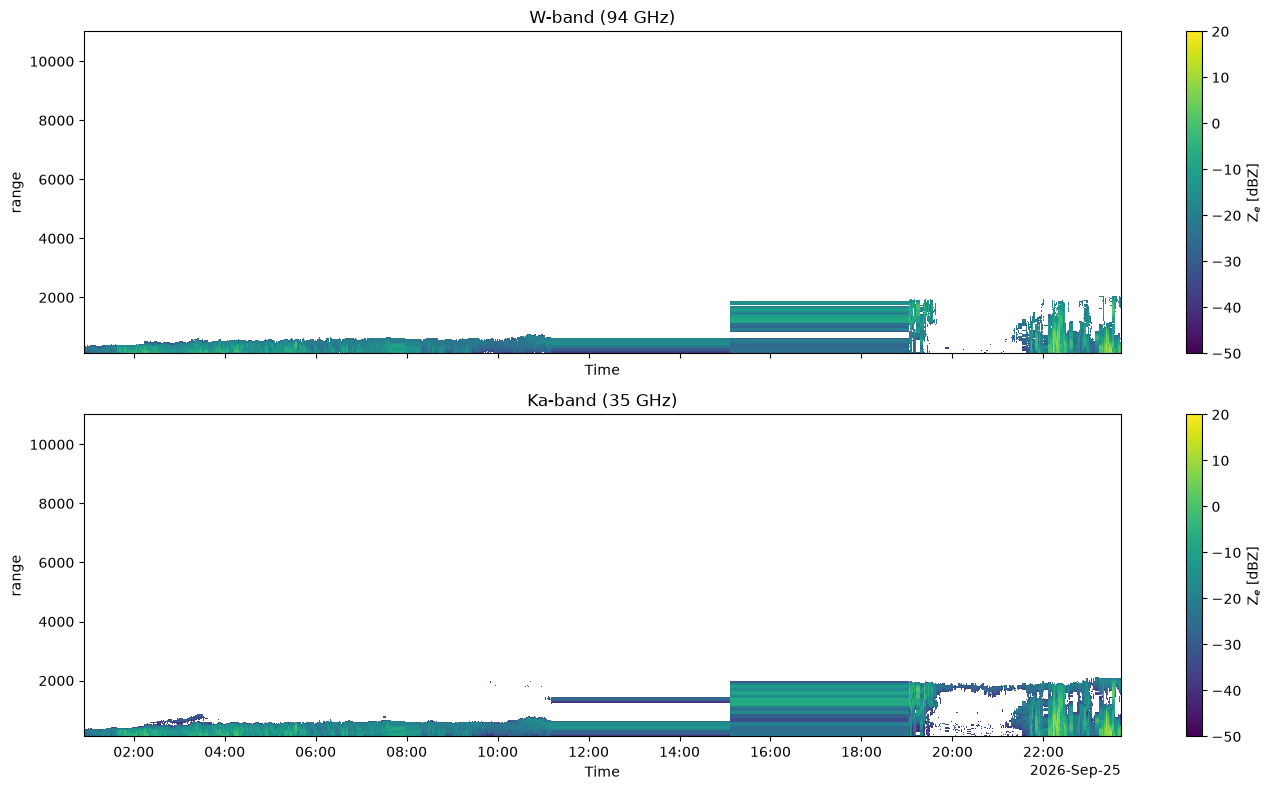

In [197]:
# Cell 8 — Side-by-side plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
ze_w_c.plot(x="Time", y="range", ax=axes[0], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[0].set_title("W-band (94 GHz)")
ze_ka_c.plot(x="Time", y="range", ax=axes[1], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[1].set_title("Ka-band (35 GHz)")
plt.tight_layout()
plt.show()

(array([2.0000e+00, 0.0000e+00, 1.3000e+01, 1.0400e+02, 2.0000e+02,
        3.6400e+02, 5.5200e+02, 8.0100e+02, 1.0010e+03, 1.2010e+03,
        1.3350e+03, 1.5130e+03, 1.6600e+03, 1.9170e+03, 2.0510e+03,
        2.3030e+03, 2.5960e+03, 2.6750e+03, 2.8430e+03, 3.1330e+03,
        3.3330e+03, 3.5890e+03, 3.8460e+03, 4.1860e+03, 4.3220e+03,
        4.5220e+03, 4.7890e+03, 4.9530e+03, 5.1220e+03, 5.2030e+03,
        5.6970e+03, 6.0260e+03, 6.5850e+03, 6.9640e+03, 7.4090e+03,
        7.7900e+03, 8.2830e+03, 9.2590e+03, 1.0481e+04, 1.2588e+04,
        1.3822e+04, 1.4211e+04, 1.4239e+04, 1.3920e+04, 1.4097e+04,
        1.4224e+04, 1.3962e+04, 1.3701e+04, 1.3949e+04, 1.3735e+04,
        1.2519e+04, 1.1291e+04, 1.0165e+04, 9.8350e+03, 9.2530e+03,
        8.6870e+03, 8.4450e+03, 7.9870e+03, 7.5340e+03, 7.0240e+03,
        6.5900e+03, 6.1730e+03, 5.8150e+03, 5.3860e+03, 4.6790e+03,
        4.2240e+03, 3.8490e+03, 3.3450e+03, 2.9950e+03, 2.4790e+03,
        2.0590e+03, 1.8420e+03, 1.5330e+03, 1.44

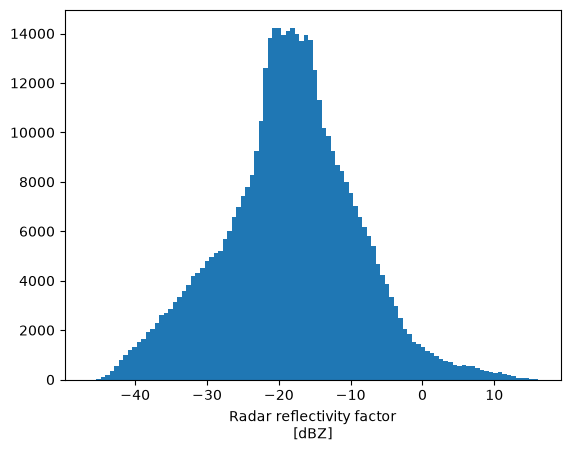

In [198]:
ze_ka.plot.hist(bins=100)

TEMPERATURE

==================================================================================================================================================

The T Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Temperature Profile in T_Alts, because Temperature Profile T_Prof only has Indices 1,2,3,.... Afterwards T_Prof uses T_Alts Altitudes and then the Values are interpolated onto the range grid

==================================================================================================================================================

In [199]:
mwr = xr.open_dataset(MWR_FILE)

In [200]:
mwr

<xarray.Dataset> Size: 226kB
Dimensions:                           (time: 144, height: 94)
Coordinates:
  * time                              (time) datetime64[ns] 1kB 2026-09-25T00...
  * height                            (height) float32 376B 275.0 ... 1.028e+04
Data variables: (12/13)
    latitude                          (time) float32 576B ...
    longitude                         (time) float32 576B ...
    altitude                          (time) float32 576B ...
    quality_flag                      (time) float64 1kB ...
    quality_flag_status               (time) float64 1kB ...
    elevation_angle                   (time) float32 576B ...
    ...                                ...
    temperature                       (time, height) float32 54kB ...
    temperature_quality_flag          (time) float64 1kB ...
    temperature_quality_flag_status   (time) float64 1kB ...
    relative_humidity                 (time, height) float32 54kB ...
    potential_temperature             (time, height) float32 54kB ...
    equivalent_potential_temperature  (time, height) float32 54kB ...
Attributes: (12/16)
    year:                         2026
    month:                        09
    day:                          25
    location:                     Pallasjärvi
    source:                       RPG-Radiometer Physics HATPRO\nVaisala CL31
    Conventions:                  CF-1.8
    ...                           ...
    history:                      2026-09-26 12:13:16 +00:00 - MWR multiple-p...
    source_file_uuids:            783a1c24-8390-40cb-b7c6-4564f424b958
    mwrpy_version:                1.7.1
    instrument_pid:               https://hdl.handle.net/21.12132/3.46797fd61...
    pid:                          https://hdl.handle.net/21.12132/1.301582283...
    cloudnet_processing_version:  2.65.8

In [201]:
# =====================================================================================
# CELL 25 - TEMPERATURE / HUMIDITY / PRESSURE PROFILES ONTO THE RADAR GRID
# Works for any source that gives values on (time x height above sea level).
# Replaces steps 24, 25 and 28 (TProf/AHProf no longer exist in the Cloudnet radar files).
# =====================================================================================

def profile_to_common_grid(profile_values, profile_times, profile_heights_asl, max_time_gap_minutes=60):
    """(source times x source heights) -> (common_times x common_range):
    first interpolate every source profile in height, then in time."""
    # Height of each common gate above mean sea level. Cloudnet 'altitude' = site altitude above mean sea
    # level (CloudnetPy metadata.py); the radar points vertically, so gate height = range + altitude
    # (Cloudnet computes its own 'height' variable the same way: cloudnet_instrument.py, add_height).
    common_heights_asl = common_range + float(ds_ka["altitude"].median())
    values  = np.asarray(profile_values, dtype=float)                                     # (source times, levels)
    heights = np.broadcast_to(np.asarray(profile_heights_asl, dtype=float), values.shape)   # 1-D heights -> every time
    on_radar_heights = np.full((values.shape[0], common_range.size), np.nan)
    for i in range(values.shape[0]):                                  # one source profile at a time
        usable = np.isfinite(values[i]) & np.isfinite(heights[i])     # skip missing levels
        if usable.sum() < 2:
            continue                                                  # empty profile -> stays NaN
        order = np.argsort(heights[i][usable])                        # np.interp needs increasing heights
        on_radar_heights[i] = np.interp(common_heights_asl,
                                        heights[i][usable][order], values[i][usable][order],
                                        right=np.nan)                 # above the profile top: no value
                                                                      # (below the lowest level: lowest value)
    profile = xr.DataArray(on_radar_heights, dims=("profile_time", "range"),
                           coords={"profile_time": np.asarray(profile_times).astype("datetime64[ns]"),
                                   "range": common_range})
    # NEW 1: drop source profiles without any value (MWR gap, rain/quality flag). Otherwise a single empty
    # profile makes every radar time between its two neighbours NaN; now the interpolation bridges it.
    profile = profile.dropna("profile_time", how="all")
    common_time_axis = xr.DataArray(common_times, dims="Time", coords={"Time": common_times})
    # Between two source profiles: linear interpolation in time (as before).
    linear = profile.interp(profile_time=common_time_axis).drop_vars("profile_time")
    # NEW 2: before the first / after the last source profile, linear interpolation has nothing on one side
    # and gives NaN -> use the nearest source profile there instead.
    nearest = profile.sel(profile_time=common_time_axis, method="nearest")
    time_to_nearest_profile = np.abs(nearest["profile_time"].values - common_times)
    on_common_grid = linear.fillna(nearest.drop_vars("profile_time"))
    # NEW 3: no source profile within max_time_gap_minutes -> no value, instead of stretching one profile
    # over hours. (My choice: 60 min; temperature changes slowly, but not over a whole afternoon.)
    too_far = xr.DataArray(time_to_nearest_profile > np.timedelta64(max_time_gap_minutes, "m"),
                           dims="Time", coords={"Time": common_times})
    return on_common_grid.where(~too_far)


# ---------- OPTION A: Cloudnet CATEGORIZE file (your supervisor's suggestion) ----------
# temperature [K], pressure [Pa], q [kg/kg] on (model_time, model_height); model_height is above mean
# sea level (CloudnetPy categorize.py). These are the weather MODEL's fields, copied from the model file -
# not measurements. Don't use 'Tw': that is wet-bulb temperature.
# categorize = xr.open_dataset(CATEGORIZE_FILE)
# model_grid = dict(profile_times=categorize["model_time"].values,
#                   profile_heights_asl=categorize["model_height"].values)
# T_on_range = profile_to_common_grid(categorize["temperature"].values, **model_grid).rename("T_cloud")   # K
# pressure_pa = profile_to_common_grid(categorize["pressure"].values, **model_grid)                       # Pa
# specific_humidity = profile_to_common_grid(categorize["q"].values, **model_grid)                        # kg/kg
# # Absolute humidity = q x air density; air density = p / (R_d * T_virtual), T_virtual = T * (1 + 0.608 q).
# AH_on_range = (1000.0 * specific_humidity * pressure_pa
#                / (287.05 * T_on_range * (1 + 0.608 * specific_humidity))).rename("AH_cloud")           # g m-3
# P_cloud = (pressure_pa / 100.0).rename("P_cloud")                                                       # hPa

# ---------- OPTION B: Cloudnet MWR product (mwr-single or mwr-multi) ----------
# temperature [K] and absolute_humidity [kg m-3] on (time, height); height is above mean sea level
# (mwrpy level2/lev2_meta_nc.py, which Cloudnet uses to make these products). No pressure profile ->
# keep your barometric P_cloud cell (step 32) with this option.
mwr = xr.open_dataset(MWR_FILE)

# ---------- 1) CHECK what the file contains: names, dimensions, units, value ranges ----------
for name in ("temperature", "relative_humidity", "height", "time"):
    if name not in mwr:
        print(f"{name:18s} NOT IN FILE -> look at print(mwr) for the right name")
        continue
    variable = mwr[name]
    if variable.dtype.kind in "fi":                                   # numbers: show min and max
        value_range = f"{float(variable.min()):.2f} to {float(variable.max()):.2f}"
    else:                                                             # time stamps: show first and last
        value_range = f"{variable.values[0]} to {variable.values[-1]}"
    print(f"{name:18s} dims {variable.dims} | units {variable.attrs.get('units')!r} | "
          f"{variable.attrs.get('long_name', '')!r} | {value_range}")

# ---------- 2) TEMPERATURE -> Kelvin ----------
temperature = mwr["temperature"].transpose("time", ...)              # make sure the order is (time, height)
if float(temperature.max()) < 100:          # no air temperature is below 100 K, so values below 100 must be degC
    print("temperature looks like degC -> converting to K")
    temperature = temperature + 273.15
temperature_k = temperature.values

# ---------- 3) RELATIVE HUMIDITY -> fraction 0..1 ----------
# Cloudnet/mwrpy stores it as a fraction (units "1"); other files use %. Values above 1.5 can only be %.
relative_humidity = mwr["relative_humidity"].transpose("time", ...)
if float(relative_humidity.max()) > 1.5:
    print("relative humidity looks like % -> converting to fraction")
    relative_humidity = relative_humidity / 100.0
relative_humidity_fraction = relative_humidity.values
assert relative_humidity_fraction.shape == temperature_k.shape, "T and RH are on different grids - tell me"

# ---------- 4) RELATIVE -> ABSOLUTE HUMIDITY, on the MWR's own grid ----------
# Saturation vapour pressure over liquid water, Magnus formula (Alduchov & Eskridge 1996), T in degC -> Pa.
temperature_c = temperature_k - 273.15
saturation_vapour_pressure_pa = 611.94 * np.exp(17.625 * temperature_c / (temperature_c + 243.04))
# Relative humidity = vapour pressure / saturation vapour pressure  ->  vapour pressure:
vapour_pressure_pa = relative_humidity_fraction * saturation_vapour_pressure_pa
# Ideal gas law for water vapour: absolute humidity = e / (R_v * T), R_v = 461.5 J kg-1 K-1 -> kg m-3, x1000 -> g m-3.
# (No pressure needed for this conversion.)
absolute_humidity_g_m3 = 1000.0 * vapour_pressure_pa / (461.5 * temperature_k)

# ---------- 5) ONTO THE RADAR GRID (function from the top of this cell) ----------
# profile_to_common_grid expects heights above MEAN SEA LEVEL. If the height check above says
# "above ground", use: mwr["height"].values + float(ds_ka["altitude"].median())
mwr_grid = dict(profile_times=mwr["time"].values, profile_heights_asl=mwr["height"].values)
T_on_range  = profile_to_common_grid(temperature_k, **mwr_grid).rename("T_cloud")              # K
AH_on_range = profile_to_common_grid(absolute_humidity_g_m3, **mwr_grid).rename("AH_cloud")    # g m-3

T_on_range.attrs["units"] = "K"
AH_on_range.attrs["units"] = "g m-3"
print(f"T : {float(T_on_range.min()):.1f} to {float(T_on_range.max()):.1f} K, shape {T_on_range.shape}")
print(f"AH: {float(AH_on_range.min()):.2f} to {float(AH_on_range.max()):.2f} g m-3")

temperature        dims ('time', 'height') | units 'K' | 'Temperature' | 225.16 to 283.85
relative_humidity  dims ('time', 'height') | units '1' | 'Relative humidity' | 0.04 to 1.38
height             dims ('height',) | units 'm' | 'Height above mean sea level' | 275.00 to 10275.00
time               dims ('time',) | units None | 'Time UTC' | 2026-09-25T00:02:23.999996781 to 2026-09-25T23:52:25.996856689
T : 225.3 to 282.4 K, shape (21680, 317)
AH: 0.02 to 9.06 g m-3


In [202]:
profile_without_T = T_on_range.sel(range=slice(0, 4000)).isnull().all("range").values
print("radar profiles without T:", int(profile_without_T.sum()),
      "| from", common_times[profile_without_T][:1], "to", common_times[profile_without_T][-1:])
print("radar:", common_times[0], "->", common_times[-1])
print("MWR  :", mwr.time.values[0], "->", mwr.time.values[-1],
      "| empty MWR profiles at:", mwr.time.values[np.isnan(temperature_k).all(axis=1)])

radar profiles without T: 0 | from [] to []
radar: 2026-09-25T00:54:34.313950538 -> 2026-09-25T23:42:09.341125488
MWR  : 2026-09-25T00:02:23.999996781 -> 2026-09-25T23:52:25.996856689 | empty MWR profiles at: []


In [203]:
print(T_on_range.shape)                                # should match ze_w_c.shape
print(f"{float(T_on_range.min()):.1f} → {float(T_on_range.max()):.1f} °K")
print("NaN in T below 4 km:", int(T_on_range.sel(range=slice(0, 4000)).isnull().sum()), "(should be 0)")
# Expect roughly: -60 → +20 °C  for Cabauw autumn

(21680, 317)
225.3 → 282.4 °K
NaN in T below 4 km: 0 (should be 0)


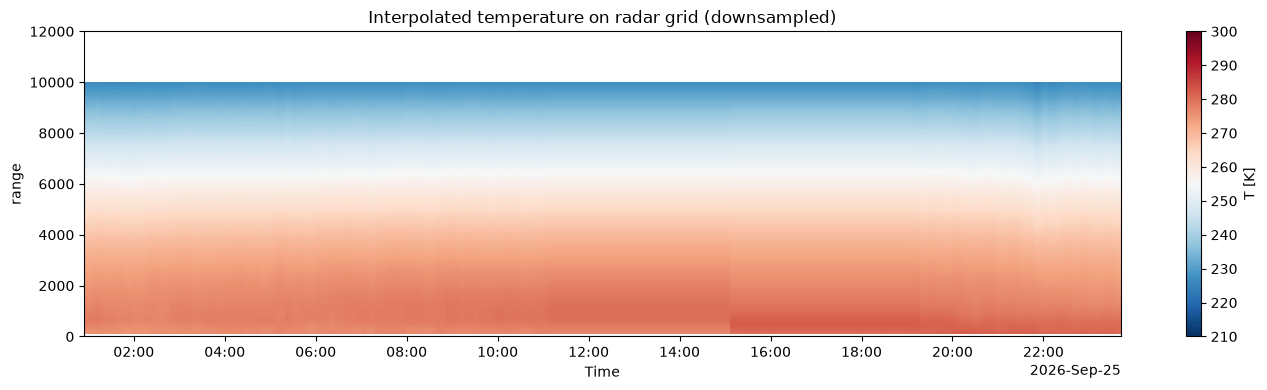

In [204]:

fig, ax = plt.subplots(1, 1, figsize=(14, 4))

T_on_range.isel(Time=slice(0, None, 5)).plot(
    x="Time",
    y="range",
    ax=ax,
    cmap="RdBu_r",
    vmin=210,
    vmax=300,
    cbar_kwargs={"label": "T [K]"},
)

ax.axhline(0, ls="--", c="k", lw=0.8, alpha=0.5)
ax.set_ylim(0, 12000)
ax.set_title("Interpolated temperature on radar grid (downsampled)")

plt.tight_layout()
plt.show()


HUMIDITY FOR DATA SAVING

The AH Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Humidity Profile in HAlts, because Humidity Profile AHProf only has Indices 1,2,3,.... in HAlt.       Afterwards AH_Prof uses HAlts Altitudes and then the Values are interpolated onto the range grid

In [205]:
print(AH_on_range)
print(AH_on_range.dims)
print(AH_on_range.shape)

<xarray.DataArray 'AH_cloud' (Time: 21680, range: 317)> Size: 55MB
array([[7.0612923 , 7.00839886, 6.95080859, ...,        nan,        nan,
               nan],
       [7.06125773, 7.00836824, 6.95078154, ...,        nan,        nan,
               nan],
       [7.06122316, 7.00833763, 6.9507545 , ...,        nan,        nan,
               nan],
       ...,
       [8.57619289, 8.51450484, 8.44860326, ...,        nan,        nan,
               nan],
       [8.5762981 , 8.51460647, 8.44869767, ...,        nan,        nan,
               nan],
       [8.57640332, 8.5147081 , 8.44879208, ...,        nan,        nan,
               nan]], shape=(21680, 317))
Coordinates:
  * Time     (Time) datetime64[ns] 173kB 2026-09-25T00:54:34.313950538 ... 20...
  * range    (range) float64 3kB 119.2 149.1 178.9 ... 1.096e+04 1.1e+04
Attributes:
    units:    g m-3
('Time', 'range')
(21680, 317)


LWP FOR DATA SAVING

In [206]:
# ---------- step 30: LWP ----------
# W radar LWP in g m-2. Which name exists depends on the loader you used in step 3:
# 'LWP' (old-name loader, already converted) or Cloudnet's 'lwp' in kg m-2 (CloudnetPy rpg.py convert_units).
lwp_w = ds_w["LWP"] if "LWP" in ds_w else ds_w["lwp"] * 1000.0
lwp = w_at_common_times(lwp_w).rename("LWP")
lwp.attrs["units"] = "g m-2"


PRESSURE FOR DATA SAVING

In [207]:
# ---------- step 31: surface pressure (only needed with the MWR option) ----------
surface_pressure_w = ds_w["SurfPres"] if "SurfPres" in ds_w else ds_w["air_pressure"] / 100.0   # Pa -> hPa
print("valid fraction of surface pressure:", float(surface_pressure_w.notnull().mean()))


valid fraction of surface pressure: 1.0


exponential atmosphere (constant scale height)

In [208]:
# Surface pressure (hPa)
surface_pressure = w_at_common_times(surface_pressure_w).values

# Radar heights (m)
radar_range = ze_w_c["range"].values

# Create an empty array for the pressure profile
pressure_profile = np.zeros((len(ze_w_c.Time), len(ze_w_c.range)))

# Atmospheric scale height (m)
scale_height = 8000.0     #H=R_d*​T/g​       8000 for T= 273K ; At 288 K --> H=8427 m     ; At 250 K --> H=7310 m          Couple % difference and more in higher regions of clouds. In lower just a few % difference.

# Loop over all time steps
for t in range(len(surface_pressure)):

    # Surface pressure at this time
    p0 = surface_pressure[t]

    # Loop over all radar gates
    for r in range(len(radar_range)):

        height = radar_range[r]

        pressure_profile[t, r] = p0 * np.exp(-height / scale_height)

# Convert to xarray
P_cloud = xr.DataArray(
    pressure_profile,
    coords={
        "Time": ze_w_c["Time"],
        "range": ze_w_c["range"]
    },
    dims=("Time", "range"),
    name="P_cloud"
)

P_cloud.attrs["units"] = "hPa"
P_cloud.attrs["long_name"] = "Pressure profile"

In [209]:
print(P_cloud)
print(P_cloud.dims)
print(P_cloud.shape)

<xarray.DataArray 'P_cloud' (Time: 21680, range: 317)> Size: 55MB
array([[971.31329548, 967.70046044, 964.10106164, ..., 251.76576926,
        250.58345404, 249.40672152],
       [971.31329548, 967.70046044, 964.10106164, ..., 251.76576926,
        250.58345404, 249.40672152],
       [971.31329548, 967.70046044, 964.10106164, ..., 251.76576926,
        250.58345404, 249.40672152],
       ...,
       [963.72720759, 960.14258929, 956.57130228, ..., 249.79944464,
        248.62636345, 247.45882137],
       [963.72720759, 960.14258929, 956.57130228, ..., 249.79944464,
        248.62636345, 247.45882137],
       [963.72720759, 960.14258929, 956.57130228, ..., 249.79944464,
        248.62636345, 247.45882137]], shape=(21680, 317))
Coordinates:
  * Time     (Time) datetime64[ns] 173kB 2026-09-25T00:54:34.313950538 ... 20...
  * range    (range) float64 3kB 119.2 149.1 178.9 ... 1.096e+04 1.1e+04
Attributes:
    units:      hPa
    long_name:  Pressure profile
('Time', 'range')
(21680, 317)


Hypsometric Equation

In [210]:
# # Physical constants
# g = 9.80665          # m/s²
# R_d = 287.05         # J/(kg K)

# # Surface pressure (hPa)
# surface_pressure = ds_w["SurfPres"]

# # Radar heights (m)
# radar_range = ze_w_c["range"].values

# # Temperature on the radar grid (K)
# temperature = T_on_range.values

# # Create an empty array
# pressure_profile = np.zeros(
#     temperature.shape,
#     dtype=np.float32
# )

# # Loop over every radar profile
# for t in range(len(surface_pressure)):

#     # Pressure at the first radar gate
#     pressure_profile[t, 0] = surface_pressure.values[t]

#     # Loop upward through the atmosphere
#     for r in range(1, len(radar_range)):

#         # Height difference between two radar gates
#         dz = radar_range[r] - radar_range[r - 1]

#         # Mean temperature between the two gates
#         T_mean = 0.5 * (
#             temperature[t, r] +
#             temperature[t, r - 1]
#         )

#         # Pressure at the current gate
#         pressure_previous = pressure_profile[t, r - 1]

#         # Hypsometric equation
#         pressure_profile[t, r] = (
#             pressure_previous *
#             np.exp(-g * dz / (R_d * T_mean))
#         )

# # Convert to xarray
# P_cloud = xr.DataArray(
#     pressure_profile,
#     coords={
#         "Time": ze_w_c["Time"],
#         "range": ze_w_c["range"]
#     },
#     dims=("Time", "range"),
#     name="P_cloud"
# )

# P_cloud.attrs["units"] = "hPa"
# P_cloud.attrs["long_name"] = "Pressure profile"

Mean Doppler Velocities

In [211]:
print(f"After alignment: W={MeanVel_W_c.shape}, Ka={MeanVel_Ka_c.shape}")
assert MeanVel_W_c.shape == MeanVel_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(21680, 317), Ka=(21680, 317)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

SAVE DATA

==================================================================================================================================================

In [212]:
# =====================================================================================
# CELL 47 - SAVE   (the SLv/SLh lines are gone; method recorded in the file)
# =====================================================================================
ds_out = xr.Dataset(
    {
        "MeanVel_W":  MeanVel_W_c.rename("MeanVel_W"),
        "MeanVel_Ka": MeanVel_Ka_c.rename("MeanVel_Ka"),
        "Ze_W":       ze_w_c.rename("Ze_W"),
        "Ze_Ka":      ze_ka_c.rename("Ze_Ka"),
        "T_cloud":    T_on_range,
        "AH_cloud":   AH_on_range,
        "P_cloud":    P_cloud,
        "LWP":        lwp,
    },
    attrs={
        "description": "Ka and W on a common time/range grid + T, AH, P for the LWC retrieval",
        "date": "20260925",
        "site": "Pallasjarvi",
        "range_matching": RANGE_MATCHING_METHOD,
        "source": "Cloudnet radar files (Ka, W); T/AH/P from RPG-Radiometer Physics HATPRO",
        "Ze_units": "dBZ",
        "P_units": "hPa",
        "MeanVel_units": "m/s",
        "LWP_units": "g m-2",
        "created_by": "02_align.ipynb",
    },
)
# xarray silently merges different time/range axes into one bigger axis; this stops that.
assert ds_out.sizes["Time"] == common_times.size and ds_out.sizes["range"] == common_range.size, ds_out.sizes
out_path = Path(f"../data/processed/{Processed_Dataset}/aligned_LWP2.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_out.to_netcdf(out_path)
print(f"Saved → {out_path}")
print(ds_out)


Saved → ..\data\processed\20260925_pallas_interpolation_CLARA\aligned_LWP2.nc
<xarray.Dataset> Size: 385MB
Dimensions:     (Time: 21680, range: 317)
Coordinates:
  * Time        (Time) datetime64[ns] 173kB 2026-09-25T00:54:34.313950538 ......
  * range       (range) float64 3kB 119.2 149.1 178.9 ... 1.096e+04 1.1e+04
Data variables:
    MeanVel_W   (Time, range) float64 55MB 0.2883 0.1756 0.1186 ... nan nan nan
    MeanVel_Ka  (Time, range) float64 55MB 0.2916 0.1687 0.141 ... nan nan nan
    Ze_W        (Time, range) float64 55MB -30.59 -28.12 -26.4 ... nan nan nan
    Ze_Ka       (Time, range) float64 55MB -28.8 -27.71 -25.06 ... nan nan nan
    T_cloud     (Time, range) float64 55MB 275.9 275.9 275.9 ... nan nan nan
    AH_cloud    (Time, range) float64 55MB 7.061 7.008 6.951 ... nan nan nan
    P_cloud     (Time, range) float64 55MB 971.3 967.7 964.1 ... 248.6 247.5
    LWP         (Time) float32 87kB 22.39 22.6 22.33 22.01 ... 45.16 40.31 47.97
Attributes:
    description:     Ka 

In [213]:
# Check if LWP exists in Ka dataset
print("Ka variables:")
print(ds_ka.data_vars)

print("\nW variables:")
print(ds_w.data_vars)

Ka variables:
Data variables:
    file_code                 (Time) int32 87kB ...
    program_number            (Time) int32 87kB ...
    model_number              int32 4B ...
    Freq                      float32 4B 35.0
    antenna_separation        float32 4B ...
    antenna_diameter          float32 4B ...
    antenna_gain              float32 4B ...
    half_power_beam_width     float32 4B 0.84
    dual_polarization         int32 4B 2
    sample_duration           (Time) float32 87kB ...
    latitude                  (Time) float32 87kB 68.02 68.02 ... 68.02 68.02
    longitude                 (Time) float32 87kB 24.16 24.16 ... 24.16 24.16
    calibration_interval      (Time) int32 87kB ...
    DoppLen                   (Time, chirp_sequence) int32 260kB 256 256 ... 256
    chirp_start_indices       (Time, chirp_sequence) int32 260kB 0 36 ... 36 98
    AvgNum                    (Time, chirp_sequence) int32 260kB 4096 ... 4096
    SeqIntTime                (Time, chirp_sequence) 

Trying Things

## Instrument table and Chirp Table

In [214]:
ds_w

<xarray.Dataset> Size: 449MB
Dimensions:                   (Time: 26916, chirp_sequence: 3, range: 317)
Coordinates:
  * Time                      (Time) datetime64[ns] 215kB 2026-09-25T00:54:34...
  * range                     (range) float32 1kB 119.2 149.1 ... 1.1e+04
Dimensions without coordinates: chirp_sequence
Data variables: (12/55)
    file_code                 (Time) int32 108kB ...
    program_number            (Time) int32 108kB ...
    model_number              int32 4B ...
    Freq                      float32 4B 94.0
    antenna_separation        float32 4B ...
    antenna_diameter          float32 4B ...
    ...                        ...
    srho_hv                   (Time, range) float32 34MB ...
    kdp                       (Time, range) float32 34MB ...
    differential_attenuation  (Time, range) float32 34MB ...
    altitude                  (Time) float32 108kB 275.0 275.0 ... 275.0 275.0
    zenith_angle              (Time) float32 108kB ...
    height                    (range) float32 1kB 394.2 424.1 ... 1.127e+04
Attributes: (12/15)
    Conventions:                  CF-1.8
    cloudnetpy_version:           1.96.5
    file_uuid:                    5b60d115-9cd4-45c6-8045-ed1b57511bee
    cloudnet_file_type:           radar
    title:                        RPG-FMCW-94 cloud radar from Pallasjärvi
    year:                         2026
    ...                           ...
    history:                      2026-09-26 00:04:23 +00:00 - radar file cre...
    source:                       RPG-Radiometer Physics RPG-FMCW-94
    references:                   https://doi.org/10.21105/joss.02123
    pid:                          https://hdl.handle.net/21.12132/1.5b60d1159...
    cloudnet_processing_version:  2.65.8
    instrument_pid:               https://hdl.handle.net/21.12132/3.b9ff0d239...

In [215]:
ds_ka

<xarray.Dataset> Size: 361MB
Dimensions:                   (Time: 21680, chirp_sequence: 3, range: 317)
Coordinates:
  * Time                      (Time) datetime64[ns] 173kB 2026-09-25T00:54:34...
  * range                     (range) float32 1kB 119.2 149.1 ... 1.1e+04
Dimensions without coordinates: chirp_sequence
Data variables: (12/55)
    file_code                 (Time) int32 87kB ...
    program_number            (Time) int32 87kB ...
    model_number              int32 4B ...
    Freq                      float32 4B 35.0
    antenna_separation        float32 4B ...
    antenna_diameter          float32 4B ...
    ...                        ...
    srho_hv                   (Time, range) float32 27MB ...
    kdp                       (Time, range) float32 27MB ...
    differential_attenuation  (Time, range) float32 27MB ...
    altitude                  (Time) float32 87kB 275.0 275.0 ... 275.0 275.0
    zenith_angle              (Time) float32 87kB ...
    height                    (range) float32 1kB ...
Attributes: (12/15)
    Conventions:                  CF-1.8
    cloudnetpy_version:           1.96.5
    file_uuid:                    215476d3-3b18-4899-9ca2-796538afa9a2
    cloudnet_file_type:           radar
    title:                        RPG-FMCW-35 cloud radar from Pallasjärvi
    year:                         2026
    ...                           ...
    history:                      2026-09-26 00:04:24 +00:00 - radar file cre...
    source:                       RPG-Radiometer Physics RPG-FMCW-35
    references:                   https://doi.org/10.21105/joss.02123
    pid:                          https://hdl.handle.net/21.12132/1.215476d33...
    cloudnet_processing_version:  2.65.8
    instrument_pid:               https://hdl.handle.net/21.12132/3.cded5e334...

In [216]:
import numpy as np
import pandas as pd

C_LIGHT = 2.998e8  # m/s

def per_chirp(da):
    """(Time, chirp) -> values of the first time step; warns if they change."""
    v = np.asarray(da.values)
    if v.ndim == 2:
        if not (v == v[0]).all():
            print(f"Warning: {da.name} changes during the file")
        v = v[0]
    return np.atleast_1d(v)

def chirp_table(ds, name):
    rng     = ds["range"].values
    starts  = per_chirp(ds["chirp_start_indices"]).astype(int)
    ends    = np.append(starts[1:], rng.size)
    freq_hz = float(ds["Freq"].values) * 1e9                   # GHz -> Hz
    dr      = per_chirp(ds["range_resolution"]).astype(float)  # m
    n_spec  = per_chirp(ds["DoppLen"]).astype(float)           # Doppler FFT points
    n_avg   = per_chirp(ds["AvgNum"])                          # averaged chirps
    t_int   = per_chirp(ds["SeqIntTime"]).astype(float)        # s

    # nyquist_velocity is stored per range gate (Time, range):
    # take the value at the first gate of each chirp
    v_all = ds["nyquist_velocity"].values
    if not (v_all == v_all[0]).all():
        print("Warning: nyquist_velocity changes during the file")
    v_nyq = v_all[0, starts].astype(float)                     # m/s

    rows = []
    for i in range(starts.size):
        gates = rng[starts[i]:ends[i]]
        rows.append({
            "radar": name,
            "chirp": i + 1,
            "range_start_m": round(float(gates[0]), 1),
            "range_end_m": round(float(gates[-1]), 1),
            "range_res_m": round(dr[i], 2),
            "integration_time_s": round(t_int[i], 3),
            "n_avg_chirps": int(n_avg[i]),
            "dopp_len": int(n_spec[i]),
            "nyquist_m_s": round(v_nyq[i], 2),
            # Doppler resolution = full velocity range / number of FFT points
            "doppler_res_m_s": round(2 * v_nyq[i] / n_spec[i], 3),
            # chirp repetition frequency from v_nyq = lambda * CRF / 4
            "crf_kHz": round(4 * v_nyq[i] * freq_hz / C_LIGHT / 1e3, 2),
        })
    return pd.DataFrame(rows)

table = pd.concat([chirp_table(ds_ka, "Ka"), chirp_table(ds_w, "W")])
print(table.to_string(index=False))

# which chirp program(s) ran, and the time between profiles
for name, ds in [("Ka", ds_ka), ("W", ds_w)]:
    prog, counts = np.unique(ds["program_number"].values, return_counts=True)
    dt = np.median(np.diff(ds["Time"].values)) / np.timedelta64(1, "s")
    print(f"{name}: program_number {dict(zip(prog, counts))}, "
          f"time step {dt:.2f} s, beam width {float(ds['half_power_beam_width']):.2f} deg")

radar  chirp  range_start_m  range_end_m  range_res_m  integration_time_s  n_avg_chirps  dopp_len  nyquist_m_s  doppler_res_m_s  crf_kHz
   Ka      1          119.2       1162.7        14.91               0.458          4096       256        26.25            0.205    12.26
   Ka      2         1192.5       3011.0        13.50               0.366          4096       256        19.54            0.153     9.12
   Ka      3         3040.8      10995.8        34.07               0.183          2048       128        13.11            0.205     6.12
    W      1          119.2       1162.7        14.91               0.458          4096       256         9.77            0.076    12.26
    W      2         1192.5       3011.0        13.50               0.366          4096       256         7.27            0.057     9.12
    W      3         3040.8      10995.8        34.07               0.183          2048       128         4.88            0.076     6.12
Ka: program_number {np.int32(2): np.int64

In [217]:
ds_out

<xarray.Dataset> Size: 385MB
Dimensions:     (Time: 21680, range: 317)
Coordinates:
  * Time        (Time) datetime64[ns] 173kB 2026-09-25T00:54:34.313950538 ......
  * range       (range) float64 3kB 119.2 149.1 178.9 ... 1.096e+04 1.1e+04
Data variables:
    MeanVel_W   (Time, range) float64 55MB 0.2883 0.1756 0.1186 ... nan nan nan
    MeanVel_Ka  (Time, range) float64 55MB 0.2916 0.1687 0.141 ... nan nan nan
    Ze_W        (Time, range) float64 55MB -30.59 -28.12 -26.4 ... nan nan nan
    Ze_Ka       (Time, range) float64 55MB -28.8 -27.71 -25.06 ... nan nan nan
    T_cloud     (Time, range) float64 55MB 275.9 275.9 275.9 ... nan nan nan
    AH_cloud    (Time, range) float64 55MB 7.061 7.008 6.951 ... nan nan nan
    P_cloud     (Time, range) float64 55MB 971.3 967.7 964.1 ... 248.6 247.5
    LWP         (Time) float32 87kB 22.39 22.6 22.33 22.01 ... 45.16 40.31 47.97
Attributes:
    description:     Ka and W on a common time/range grid + T, AH, P for the ...
    date:            20260925
    site:            Pallasjarvi
    range_matching:  interpolation
    source:          Cloudnet radar files (Ka, W); T/AH/P from RPG-Radiometer...
    Ze_units:        dBZ
    P_units:         hPa
    MeanVel_units:   m/s
    LWP_units:       g m-2
    created_by:      02_align.ipynb